In [1]:
from pathlib import Path

from cr_knee_fit.analysis import FitConfig
from cr_knee_fit.cr_models.crams import CramsModel

In [2]:
config = FitConfig.model_validate_json(Path("../out/phase-7/minimal/config-dump.json").read_text())

In [3]:
from cr_knee_fit.fit_data import Data

data = Data.load(config.fit_data_config, verbose=True)

✅ AMS-02 H
✅ AMS-02 N
✅ AMS-02 O
✅ AMS-02 Ne
✅ AMS-02 Mg
✅ AMS-02 Si
✅ AMS-02 S
✅ AMS-02 Fe
✅ DAMPE H
✅ DAMPE He
✅ DAMPE C
❌ DAMPE N: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/DAMPE_N_energy.txt not found.
✅ DAMPE O
❌ DAMPE Ne: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/DAMPE_Ne_energy.txt not found.
❌ DAMPE Mg: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/DAMPE_Mg_energy.txt not found.
❌ DAMPE Si: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/DAMPE_Si_energy.txt not found.
❌ DAMPE S: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/DAMPE_S_energy.txt not found.
✅ DAMPE Fe
✅ CALET H
✅ CALET He
❌ CALET B: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/CALET_B_energy.txt not found.
✅ CALET C
❌ CALET N: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/CALET_N_energy.txt not found.
✅ CALET O
❌ CALET Ne: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/CALET_Ne_energy.txt not found.
❌ CALET Mg: /home/nj-vs

In [4]:
from cr_knee_fit.model import Model

/home/nj-vs-vh/Documents/Science/cr-knee-fit/cr_knee_fit/cr_models/crams.py:477: RuntimeWarning: divide by zero encountered in log10
  return np.log10(self.crams.compute(self.propagation, self.injection))


logposterior: -260.94496526597345
adjusted logposterior: -260.94496526597345


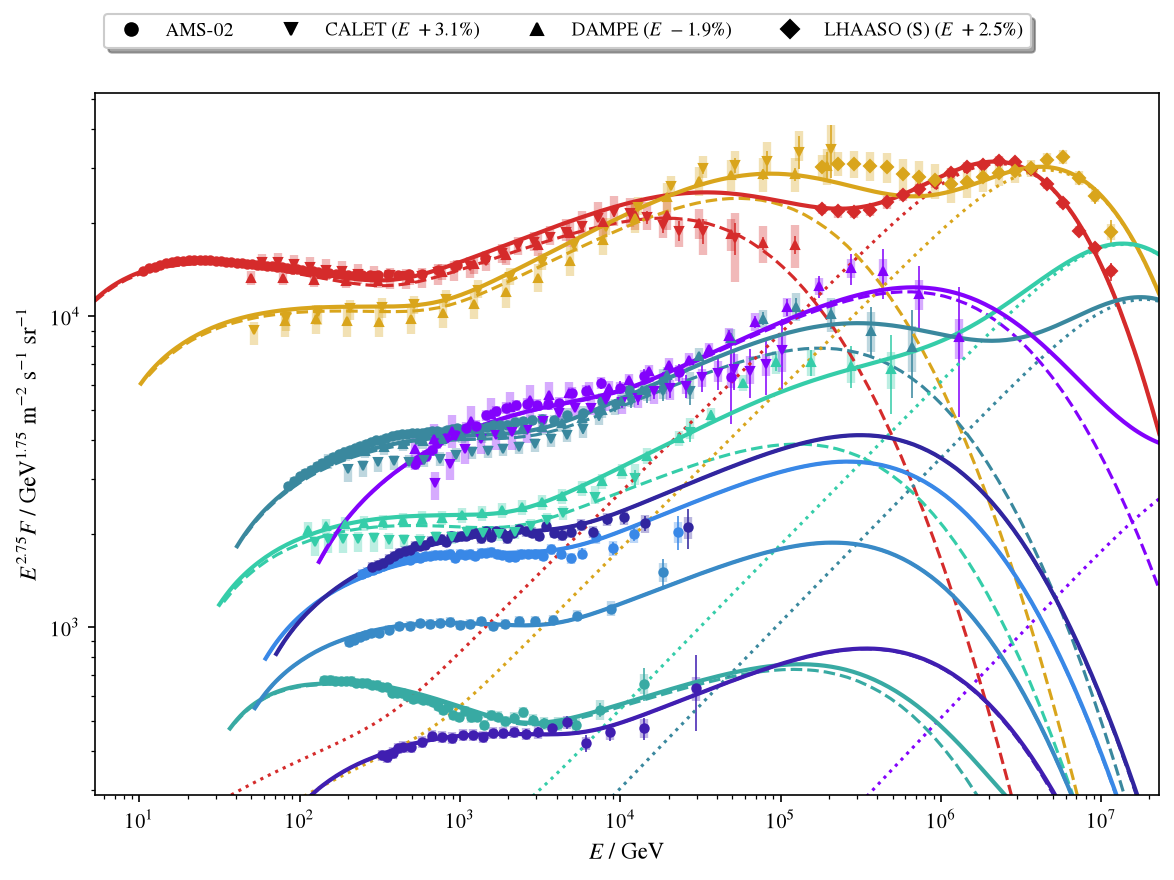

In [5]:
from cr_knee_fit.inference import logposterior

model = Model.load(Path("../out/phase-7/minimal/mle-wip.txt"), layout_info=config.model)
assert model is not None
m = model

print("logposterior:", logposterior(m, data, config=config.model))

le_crams, he_crams = m.populations
assert isinstance(le_crams, CramsModel)
assert isinstance(he_crams, CramsModel)

# le_crams.injection.abundances[0] *= 0.95
# he_crams.injection.abundances[1] *= 0.99
# he_crams.injection.abundances[5] *= 0.8
le_crams.clear_crams_cache()

# he_crams.injection.abundances[0] *= 1.5
# he_crams.injection.abundances[1] *= 1.5
# he_crams.injection.abundances[5] *= 1.5
he_crams.clear_crams_cache()

print("adjusted logposterior:", logposterior(m, data, config=config.model))

m.plot_spectra(data, scale=2.75);

In [7]:
print(le_crams.propagation)
print(he_crams.propagation)

PropagationParams(H_kpc=np.float64(7.0), v_A_km_sec=np.float64(1.0109406540137318), D_0_cm2_sec=np.float64(3.2836138636505843e+28), R_b_GV=np.float64(373.7901822155551), delta=np.float64(0.47659711249280134), ddelta=np.float64(0.3207327790158306), smoothness=0.1, X_src=np.float64(-1.0), phi=np.float64(0.5858550661968001))
PropagationParams(H_kpc=np.float64(7.0), v_A_km_sec=np.float64(1.0109406540137318), D_0_cm2_sec=np.float64(3.2836138636505843e+28), R_b_GV=np.float64(373.7901822155551), delta=np.float64(0.47659711249280134), ddelta=np.float64(0.3207327790158306), smoothness=0.1, X_src=np.float64(-1.0), phi=np.float64(0.5858550661968001))
